## **Trabajo Práctico Final: Airbnb Price - EDA**
____
__Universidad Tecnológica Nacional, Buenos Aires__\
__Ingeniería Industrial__\
__Ciencia de Datos - Curso I5521__
____

- Nombre: Facundo
- Apellido: Del Bono

En este notebook hacemos el análisis exploratorio del dataset de Airbnb, para entender de qué depende el precio por noche de las propiedades.

# Librerías

In [1]:
# Importo librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset

In [2]:
# Cargo el archivo CSV en un dataframe
df = pd.read_csv('airbnb_us.csv')

# Muestro las primeras 5 filas para ver que se haya cargado bien
df.head()

,id,property_type,room_type,amenities,accommodates,bathrooms,bed_type,cancellation_policy,cleaning_fee,city,...,longitude,name,neighbourhood,number_of_reviews,review_scores_rating,thumbnail_url,zipcode,bedrooms,beds,price
0,13418779,House,Entire home/apt,"{TV,""Cable TV"",Internet,""Wireless Internet"",Ki...",4,1.0,Real Bed,flexible,True,SF,...,-122.431619,Beautiful Flat in the Heart of SF!,Lower Haight,0,NaN,https://a0.muscache.com/im/pictures/72208dad-9...,94117.0,2.0,2.0,750.0
1,3808709,Apartment,Entire home/apt,"{TV,Internet,""Wireless Internet"",""Air conditio...",2,1.0,Real Bed,moderate,True,DC,...,-77.034596,Great studio in midtown DC,Columbia Heights,4,40.0,NaN,20009,0.0,1.0,115.0
2,12422935,Apartment,Private room,"{TV,""Wireless Internet"",Heating,""Smoke detecto...",2,1.0,Real Bed,strict,True,SF,...,-122.429526,Comfort Suite San Francisco,Noe Valley,3,100.0,https://a0.muscache.com/im/pictures/82509143-4...,94131,1.0,1.0,85.0
3,180792,House,Private room,"{TV,""Cable TV"",""Wireless Internet"",""Pets live ...",2,1.0,Real Bed,moderate,True,SF,...,-122.501095,Cozy Garden Studio - Private Entry,Richmond District,159,99.0,https://a0.muscache.com/im/pictures/0ed6c128-7...,94121,1.0,1.0,120.0
4,2658946,Apartment,Entire home/apt,"{TV,""Cable TV"",Internet,""Wireless Internet"",""A...",6,1.5,Real Bed,strict,True,DC,...,-77.031189,Charming 2 bdrm in trendy U/14th streets w/par...,U Street Corridor,13,89.0,NaN,20009,2.0,3.0,200.0


In [3]:
# Cantidad de filas y columnas
print(df.shape)

(19309, 29)


In [4]:
# Nombre de las columnas, tipo de dato y cantidad de valores no nulos
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19309 entries, 0 to 19308
Data columns (total 29 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      19309 non-null  int64  
 1   property_type           19309 non-null  str    
 2   room_type               19309 non-null  str    
 3   amenities               19309 non-null  str    
 4   accommodates            19309 non-null  int64  
 5   bathrooms               19274 non-null  float64
 6   bed_type                19309 non-null  str    
 7   cancellation_policy     19309 non-null  str    
 8   cleaning_fee            19309 non-null  bool   
 9   city                    19309 non-null  str    
 10  description             19309 non-null  str    
 11  first_review            15355 non-null  str    
 12  host_has_profile_pic    19306 non-null  str    
 13  host_identity_verified  19306 non-null  str    
 14  host_response_rate      15013 non-null  str    
 

In [5]:
# Métricas estadísticas de las variables numéricas
df.describe()

,id,accommodates,bathrooms,latitude,longitude,number_of_reviews,review_scores_rating,bedrooms,beds,price
count,1.930900e+04,19309.000000,19274.000000,19309.000000,19309.000000,19309.000000,15175.000000,19292.000000,19285.0000,19309.000000
mean,1.121819e+07,3.426485,1.276201,39.723345,-93.135683,25.086695,94.722372,1.361290,1.7888,195.225542
std,6.105064e+06,2.204776,0.586713,1.902391,21.344892,44.348377,7.097521,0.901212,1.2470,202.184231
min,9.410000e+02,1.000000,0.000000,37.704743,-122.511500,0.000000,20.000000,0.000000,0.0000,10.000000
25%,6.211289e+06,2.000000,1.000000,37.784274,-122.413368,1.000000,93.000000,1.000000,1.0000,87.000000
50%,1.215601e+07,3.000000,1.000000,38.915016,-87.625744,7.000000,97.000000,1.000000,1.0000,135.000000
75%,1.639470e+07,4.000000,1.500000,41.926857,-76.998882,28.000000,100.000000,2.000000,2.0000,220.000000
max,2.121545e+07,16.000000,8.000000,42.390437,-70.985047,542.000000,100.000000,10.000000,16.0000,1999.000000


In [6]:
# El dataset tiene 19309 publicaciones y 29 variables
# Hay variables numéricas (huespedes, baños, habitaciones, precio), categóricas (tipo de habitacion, ciudad, tipo de propiedad), y fechas que están como texto (host_since, first_review, last_review) y texto libre (description, name)
# El precio va de 10 a 1999 USD. La media de 195 es mucho mayor que la mediana de 135, por lo que hay pocas propiedades muy caras que suben el promedio

In [7]:
# Veo cuántas publicaciones hay por ciudad
df['city'].value_counts()

city
SF         6434
DC         5688
Chicago    3719
Boston     3468
Name: count, dtype: int64

In [8]:
# Hay 4 ciudades: San Francisco, Washington DC, Chicago y Boston
# San Francisco es la que más publicaciones tiene

# Limpieza

## Duplicados

In [9]:
# Cuento si hay publicaciones repetidas
print(df.duplicated().sum())

0


In [10]:
# No hay filas duplicadas

## Valores nulos

In [11]:
# Cantidad de nulos por columna
nulos = df.isnull().sum()

# Porcentaje de nulos por columna
porcentaje = df.isnull().sum() / len(df) * 100

# Junto las dos cosas en una tabla
tabla_nulos = pd.concat([nulos, porcentaje], axis=1, keys=['Cantidad', 'Porcentaje'])

# Muestro solo las columnas que tienen nulos, ordenadas de mayor a menor
tabla_nulos[tabla_nulos['Cantidad'] > 0].sort_values('Cantidad', ascending=False)

,Cantidad,Porcentaje
host_response_rate,4296,22.248692
review_scores_rating,4134,21.409705
first_review,3954,20.477498
last_review,3954,20.477498
thumbnail_url,2402,12.439795
neighbourhood,1458,7.550883
zipcode,225,1.165260
bathrooms,35,0.181263
beds,24,0.124294
bedrooms,17,0.088042


In [12]:
# host_response_rate y review_scores_rating tienen más del 20% de nulos
# si first_review y last_review tienen nulos quiere decir que son publicaciones que todavía no tienen reviews
# bathrooms, bedrooms, beds y los datos del host tienen muy pocos nulos (menos del 0,2%), lo cual indica que es un buen database.

In [13]:
# Reviso si los nulos del puntaje son publicaciones sin reviews
sin_puntaje = df[df['review_scores_rating'].isnull()]
print(len(sin_puntaje))
print((sin_puntaje['number_of_reviews'] == 0).sum())

4134
3954


In [14]:
# De las 4134 publicaciones sin puntaje, 3954 (el 96%) no tienen ninguna review
# Es decir, el nulo no es un error de carga: el puntaje falta porque nadie calificó todavía la publicación
# Por eso más adelante creamos la variable tiene_reviews, para que el modelo sepa cuáles son publicaciones nuevas

## Columnas que no vamos a usar

In [15]:
# Elimino columnas que no sirven para analizar el precio:
# id es solo un identificador, thumbnail_url es un link a una foto, name es texto libre, y zipcode repite la información de ubicación
df = df.drop(columns=['id', 'thumbnail_url', 'name', 'zipcode'])
# description la eliminamos más adelante, después de usarla para crear una variable nueva

## Tipos de datos

In [16]:
# La tasa de respuesta viene como texto (ej: '100%'), le saco el % y lo paso a número
df['host_response_rate'] = df['host_response_rate'].str.replace('%', '')
df['host_response_rate'] = df['host_response_rate'].astype(float)

In [17]:
# Estas columnas vienen como 't' y 'f', las paso a 1 y 0
df['host_has_profile_pic'] = df['host_has_profile_pic'].map({'t': 1, 'f': 0})
df['host_identity_verified'] = df['host_identity_verified'].map({'t': 1, 'f': 0})
df['instant_bookable'] = df['instant_bookable'].map({'t': 1, 'f': 0})

# La limpieza viene como True y False, también la paso a 1 y 0
df['cleaning_fee'] = df['cleaning_fee'].astype(int)

In [18]:
# Paso las fechas de texto a formato fecha
df['host_since'] = pd.to_datetime(df['host_since'])
df['first_review'] = pd.to_datetime(df['first_review'])
df['last_review'] = pd.to_datetime(df['last_review'])

## Nuevas variables

In [19]:
# Busco la fecha más reciente del dataset para usarla como referencia, y de esta forma sacar la experiencia del host
# Si tomase la fecha de hoy me daria que todos tienen muchos años de experiencia
fecha_ref = df['last_review'].max()
print(fecha_ref)

2017-10-05 00:00:00


In [20]:
# Calculo hace cuántos años el host está en Airbnb
df['host_antiguedad'] = (fecha_ref - df['host_since']).dt.days / 365

In [21]:
# Cuento la cantidad de amenities de cada propiedad (cantidad de comas + 1)
df['n_amenities'] = df['amenities'].str.count(',') + 1

# Si la lista está vacía '{}' le pongo 0
df.loc[df['amenities'] == '{}', 'n_amenities'] = 0

In [22]:
# Paso el texto de amenities a una lista: saco las llaves y las comillas, y separo por comas
lista_amenities = df['amenities'].str.replace('{', '').str.replace('}', '').str.replace('"', '').str.split(',')

# Creo una columna 0/1 para algunas amenities: vale 1 si la amenity está en la lista de la propiedad
df['am_tv'] = lista_amenities.apply(lambda x: 'TV' in x).astype(int)
df['am_kitchen'] = lista_amenities.apply(lambda x: 'Kitchen' in x).astype(int)
df['am_fireplace'] = lista_amenities.apply(lambda x: 'Indoor fireplace' in x).astype(int)
df['am_gym'] = lista_amenities.apply(lambda x: 'Gym' in x).astype(int)
df['am_pool'] = lista_amenities.apply(lambda x: 'Pool' in x).astype(int)
df['am_doorman'] = lista_amenities.apply(lambda x: 'Doorman' in x).astype(int)

In [23]:
# Variable que indica si la publicación tiene al menos una review (1) o no (0)
df['tiene_reviews'] = (df['number_of_reviews'] > 0).astype(int)

In [24]:
# Largo de la descripción (cantidad de caracteres)
df['largo_descripcion'] = df['description'].str.len()

print(df['largo_descripcion'].describe())

count    19309.000000
mean       798.066083
std        303.436978
min          1.000000
25%        547.000000
50%       1000.000000
75%       1000.000000
max       1000.000000
Name: largo_descripcion, dtype: float64


In [25]:
# Busco las publicaciones que mencionan la inauguración presidencial en la descripción
menciona_inauguracion = df['description'].str.contains('inauguration', case=False)

print(menciona_inauguracion.sum())
print(df[menciona_inauguracion].groupby('city')['price'].agg(['median', 'count']))

# Cuántas de las publicaciones de 1000 USD o más de DC la mencionan
caras_dc = (df['city'] == 'DC') & (df['price'] >= 1000)
print(caras_dc.sum(), (caras_dc & menciona_inauguracion).sum())

314
      median  count
city               
DC     500.0    314
179 69


In [26]:
# 314 publicaciones mencionan la inauguración presidencial (enero 2017) y todas son de DC, con una mediana de 500 USD
# De las 179 publicaciones de DC que cuestan 1000 USD o más, 69 mencionan la inauguración
# Esto explica parte de los precios muy altos de DC: son alquileres armados para ese evento puntual

In [27]:
# Elimino las columnas que ya transformé o que no voy a usar
# description ya la usamos para crear largo_descripcion
# first_review y last_review no las uso porque la información de reviews ya está en number_of_reviews
df = df.drop(columns=['amenities', 'host_since', 'first_review', 'last_review', 'description'])

In [28]:
# Se crearon variables nuevas:
# host_antiguedad: años que tiene el host en Airbnb (tomando como referencia la última review del dataset, 05/10/2017)
# n_amenities: cantidad de amenities que tiene la propiedad
# am_tv, am_kitchen, am_fireplace, am_gym, am_pool, am_doorman: 1 si la propiedad tiene esa amenity y 0 si no
# tiene_reviews: 1 si la publicación tiene al menos una review y 0 si no
# largo_descripcion: cantidad de caracteres de la descripción (como máximo 1000, porque el dataset la corta ahí)

## Completar nulos

In [29]:
# Las columnas con muy pocos nulos: elimino esas filas
df = df.dropna(subset=['bathrooms', 'bedrooms', 'beds', 'host_has_profile_pic'])

In [30]:
# Las columnas con muchos nulos las completo con la mediana
df['host_response_rate'] = df['host_response_rate'].fillna(df['host_response_rate'].median())
df['review_scores_rating'] = df['review_scores_rating'].fillna(df['review_scores_rating'].median())

# Los barrios que faltan los completo como 'Desconocido'
df['neighbourhood'] = df['neighbourhood'].fillna('Desconocido')

In [31]:
# Verifico que no queden nulos
print(df.isnull().sum().sum())

0


In [32]:
# Dimensiones del dataset limpio
print(df.shape)

(19243, 30)


In [33]:
# Las filas con pocos nulos las eliminamos porque eran muy pocas, alrededor del 0,3% del database
# En host_response_rate y review_scores_rating usamos la mediana porque borrar esas filas sería perder más del 20% de los datos, y la mediana no se ve afectada por valores extremos
# Nos quedamos con 19243 filas (perdimos solo 66) y 30 columnas, sin valores nulos

# Análisis del precio

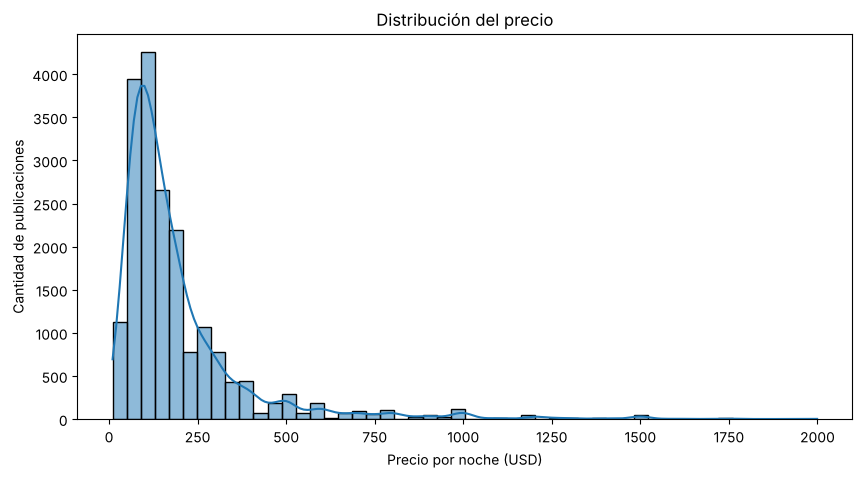

In [34]:
# Histograma del precio
plt.figure(figsize=(10,5))
sns.histplot(df['price'], bins=50, kde=True)
plt.title('Distribución del precio')
plt.xlabel('Precio por noche (USD)')
plt.ylabel('Cantidad de publicaciones')
plt.show()

In [35]:
# La distribución del precio no es simétrica, tiene una cola larga hacia la derecha (asimetría positiva)
# La mayoría de las publicaciones están entre 50 y 250 USD, pero hay algunas que llegan hasta casi 2000 USD

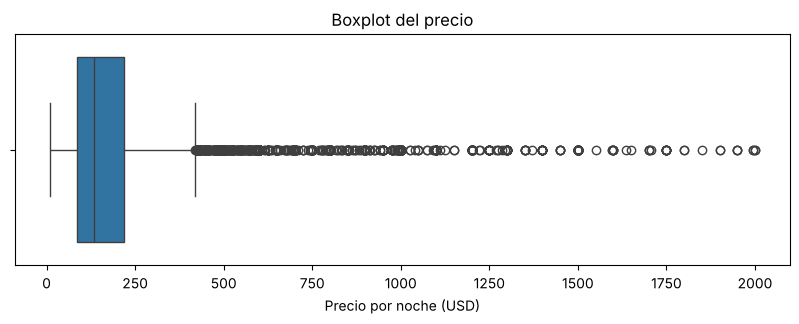

In [36]:
# Boxplot del precio para ver los valores extremos
plt.figure(figsize=(10,3))
sns.boxplot(x=df['price'])
plt.title('Boxplot del precio')
plt.xlabel('Precio por noche (USD)')
plt.show()

## Outliers

In [37]:
# Calculo los cuartiles y el rango intercuartil
q1 = df['price'].quantile(0.25)
q3 = df['price'].quantile(0.75)
iqr = q3 - q1

# Límite superior: todo lo que esté por encima se considera outlier
limite_superior = q3 + 1.5 * iqr
print(f'Límite superior: {limite_superior}')

# Cuento cuántas publicaciones superan ese límite
outliers = df[df['price'] > limite_superior]
print(f'Cantidad de outliers: {len(outliers)}')
print(f'Porcentaje de outliers: {len(outliers) / len(df) * 100:.1f}%')

Límite superior: 419.50000000000125
Cantidad de outliers: 1569
Porcentaje de outliers: 8.2%


In [38]:
# Con el criterio de 1.5 * IQR, todo precio mayor a 420 USD es outlier, y eso es el 8% del dataset (1569 publicaciones)
# Decidimos NO eliminarlos: son propiedades caras pero reales (casas grandes, zonas exclusivas) y el modelo tiene que aprender a predecirlas también
# Además, borrar el 8% de los datos es mucho
# En lugar de eliminarlos, aplicamos el logaritmo al precio para reducir el efecto de los valores extremos

## Logaritmo del precio

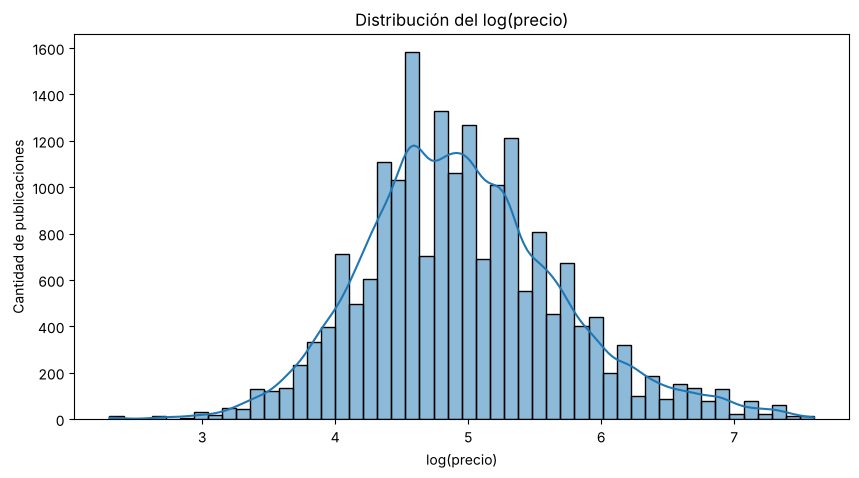

In [39]:
# Creo una columna nueva con el logaritmo del precio
df['log_price'] = np.log(df['price'])

# Histograma del log del precio
plt.figure(figsize=(10,5))
sns.histplot(df['log_price'], bins=50, kde=True)
plt.title('Distribución del log(precio)')
plt.xlabel('log(precio)')
plt.ylabel('Cantidad de publicaciones')
plt.show()

In [40]:
# Comparo la asimetría antes y después del logaritmo. Si es 0 la distribución es simétrica
print(f"Asimetría del precio: {df['price'].skew():.2f}")
print(f"Asimetría del log(precio): {df['log_price'].skew():.2f}")

Asimetría del precio: 3.52
Asimetría del log(precio): 0.42


In [41]:
# Con el logaritmo la distribución queda mucho más simétrica y parecida a una normal
# Por eso, para comparar el precio entre grupos vamos a usar log(precio) en los gráficos, y en el modelo vamos a predecir log(precio)

# Precio según variables categóricas

## Ciudad

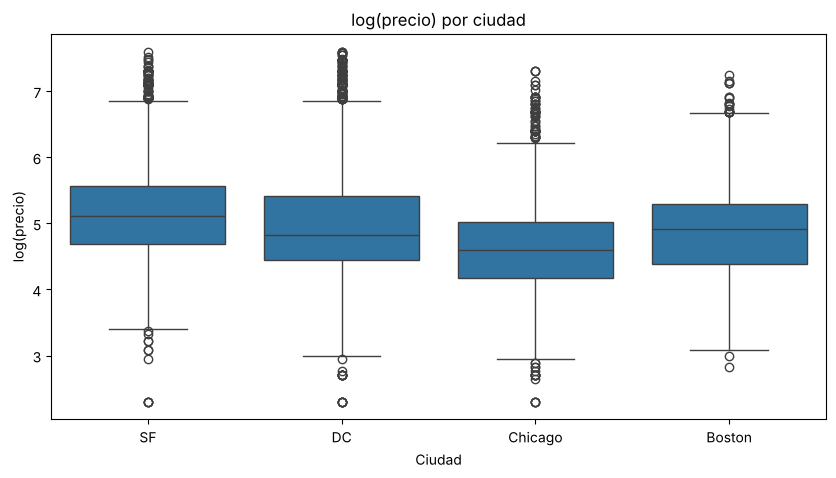

In [42]:
# Boxplot del log(precio) por ciudad
plt.figure(figsize=(10,5))
sns.boxplot(data=df, x='city', y='log_price')
plt.title('log(precio) por ciudad')
plt.xlabel('Ciudad')
plt.ylabel('log(precio)')
plt.show()

In [43]:
# Mediana, media y cantidad de publicaciones por ciudad
df.groupby('city')['price'].agg(['median', 'mean', 'count']).sort_values('median')

,median,mean,count
city,,,
Chicago,99.0,132.525437,3715
DC,125.0,218.146363,5664
Boston,136.0,165.748409,3458
SF,165.0,227.706681,6406


In [44]:
# San Francisco es la ciudad más cara (mediana 165 USD) y Chicago la más barata (mediana 99 USD)
# En DC la media (218) está muy por encima de la mediana (125): es la ciudad con más publicaciones muy caras
# Gran parte de esas publicaciones caras de DC se explican por la inauguración presidencial de enero 2017 (lo vimos en Nuevas variables)
# La ciudad influye en el precio, así que es una variable importante para el modelo

## Tipo de habitación

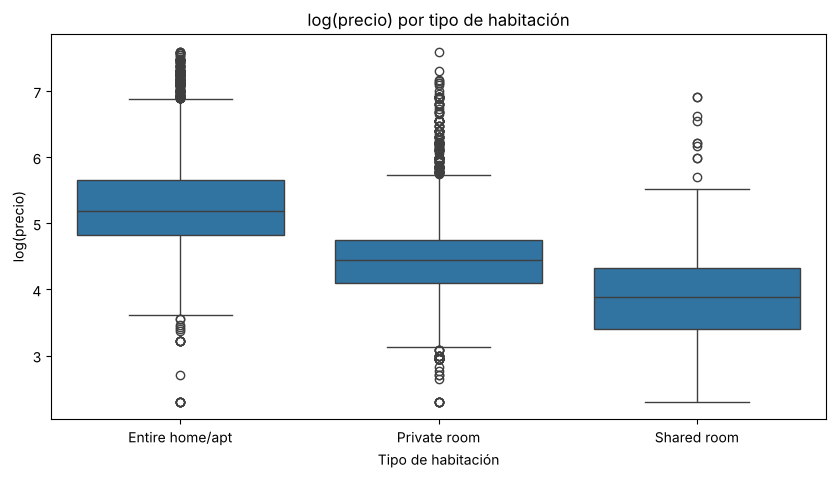

In [45]:
# Boxplot del log(precio) por tipo de habitación
plt.figure(figsize=(10,5))
sns.boxplot(data=df, x='room_type', y='log_price')
plt.title('log(precio) por tipo de habitación')
plt.xlabel('Tipo de habitación')
plt.ylabel('log(precio)')
plt.show()

In [46]:
# Mediana del precio por tipo de habitación
df.groupby('room_type')['price'].agg(['median', 'count']).sort_values('median')

,median,count
room_type,,
Shared room,49.0,377
Private room,85.0,6831
Entire home/apt,180.0,12035


In [47]:
# Es la variable categórica que más diferencia el precio:
# alquilar la propiedad entera (mediana 180 USD) cuesta el doble que una habitación privada (85 USD), y una habitación compartida es la más barata (49 USD)
# Casi no hay habitaciones compartidas (377 publicaciones, el 2%)

## Ciudad y tipo de habitación

In [48]:
# Tabla dinámica: mediana del precio por ciudad y tipo de habitación
pd.pivot_table(df, index='city', columns='room_type', values='price', aggfunc='median')

room_type,Entire home/apt,Private room,Shared room
city,,,
Boston,180.0,71.0,66.5
Chicago,131.0,60.0,31.0
DC,155.0,80.0,44.5
SF,225.0,100.0,65.0


In [49]:
# El orden se mantiene en todas las ciudades: propiedad entera > habitación privada > habitación compartida
# Y en todos los tipos de habitación San Francisco es la más cara y Chicago la más barata

## Tipo de propiedad

In [50]:
# Cantidad de publicaciones por tipo de propiedad
df['property_type'].value_counts()

property_type
Apartment             11468
House                  4789
Condominium            1566
Townhouse               500
Loft                    205
Other                   168
Bed & Breakfast         134
Guest suite              65
In-law                   64
Guesthouse               54
Boutique hotel           47
Dorm                     46
Timeshare                33
Boat                     30
Hostel                   16
Bungalow                 13
Villa                    11
Camper/RV                10
Cabin                     8
Castle                    4
Serviced apartment        3
Treehouse                 3
Yurt                      2
Tent                      1
Train                     1
Vacation home             1
Cave                      1
Name: count, dtype: int64

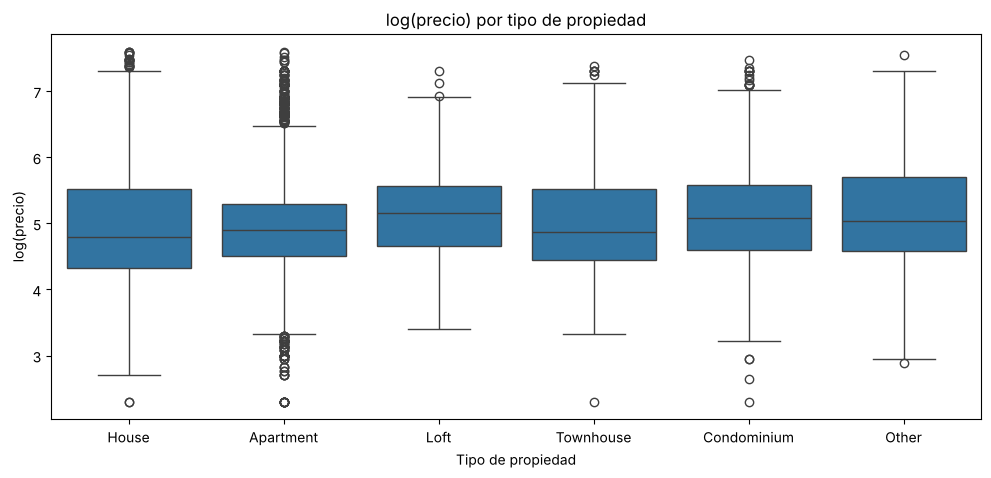

In [51]:
# Me quedo con los 6 tipos de propiedad con más publicaciones, el resto tienen muy pocas
top_propiedades = df['property_type'].value_counts().index[0:6]
df_top = df[df['property_type'].isin(top_propiedades)]

# Boxplot del log(precio) por tipo de propiedad
plt.figure(figsize=(12,5))
sns.boxplot(data=df_top, x='property_type', y='log_price')
plt.title('log(precio) por tipo de propiedad')
plt.xlabel('Tipo de propiedad')
plt.ylabel('log(precio)')
plt.show()

In [52]:
# Hay 27 tipos de propiedad pero casi todo son departamentos (60%) y casas (25%)
# Las medianas son parecidas entre tipos (entre 120 y 175 USD), los Loft y Condominium son un poco más caros
# Influye menos que el tipo de habitación

## Política de cancelación

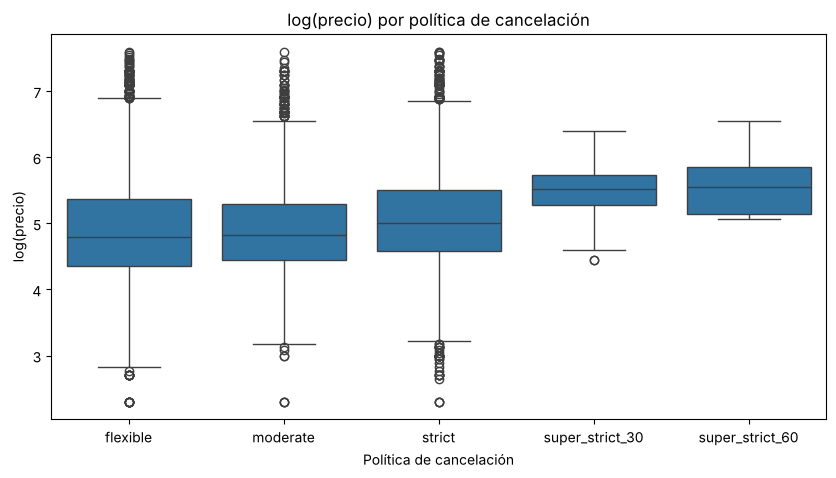

In [53]:
# Boxplot del log(precio) por política de cancelación
plt.figure(figsize=(10,5))
sns.boxplot(data=df, x='cancellation_policy', y='log_price', order=['flexible', 'moderate', 'strict', 'super_strict_30', 'super_strict_60'])
plt.title('log(precio) por política de cancelación')
plt.xlabel('Política de cancelación')
plt.ylabel('log(precio)')
plt.show()

In [54]:
# Mediana del precio por política de cancelación
df.groupby('cancellation_policy')['price'].agg(['median', 'count'])

,median,count
cancellation_policy,,
flexible,120.0,5711
moderate,125.0,5442
strict,150.0,7988
super_strict_30,249.0,97
super_strict_60,258.0,5


In [55]:
# Mientras más estricta la política de cancelación, más caro el precio (de 120 USD en flexible a 150 USD en strict)
# Las políticas super_strict son más caras pero tienen muy pocas publicaciones (102 en total), así que no son representativas

## Tipo de cama

In [56]:
# Mediana del precio por tipo de cama
df.groupby('bed_type')['price'].agg(['median', 'count']).sort_values('median')

,median,count
bed_type,,
Couch,75.0,63
Futon,75.0,160
Airbed,76.0,150
Pull-out Sofa,89.0,145
Real Bed,136.0,18725


In [57]:
# El 97% de las publicaciones tiene cama real, que es la más cara
# El resto son más baratas, pero son muy pocas publicaciones

## Variables binarias

In [58]:
# Mediana del precio según si tiene o no cada característica (0 = no, 1 = sí)
print(df.groupby('cleaning_fee')['price'].median())
print(df.groupby('instant_bookable')['price'].median())
print(df.groupby('host_identity_verified')['price'].median())

cleaning_fee
0    120.0
1    139.0
Name: price, dtype: float64
instant_bookable
0    139.0
1    128.0
Name: price, dtype: float64
host_identity_verified
0.0    144.0
1.0    130.0
Name: price, dtype: float64


In [59]:
# Las propiedades con cargo de limpieza son un poco más caras 
# Que se pueda reservar al instante o que el host esté verificado casi no cambia el precio
# Estas variables tienen poca influencia sobre el precio

## Amenities

In [60]:
# Lista de las amenities que convertimos en variables 0/1
amenities = ['am_tv', 'am_kitchen', 'am_fireplace', 'am_gym', 'am_pool', 'am_doorman']

# Para cada amenity: porcentaje de publicaciones que la tienen y mediana del precio con y sin ella
filas = []
for col in amenities:
    porcentaje = df[col].mean() * 100
    mediana_con = df[df[col] == 1]['price'].median()
    mediana_sin = df[df[col] == 0]['price'].median()
    filas.append([col, porcentaje, mediana_con, mediana_sin])

tabla_amenities = pd.DataFrame(filas, columns=['Amenity', '% publicaciones', 'Mediana con (USD)', 'Mediana sin (USD)'])
tabla_amenities.round(1)

,Amenity,% publicaciones,Mediana con (USD),Mediana sin (USD)
0,am_tv,75.8,150.0,99.0
1,am_kitchen,90.9,139.0,101.0
2,am_fireplace,15.4,175.0,129.0
3,am_gym,11.7,171.0,129.0
4,am_pool,5.2,169.0,130.0
5,am_doorman,6.1,165.0,130.0


In [61]:
# Todas las amenities elegidas se asocian a precios más altos
# Las que más diferencian son la chimenea (175 vs 129 USD), el gimnasio (171 vs 129) y la pileta (169 vs 130): son poco comunes y propias de propiedades de mayor categoría
# TV y cocina las tiene la mayoría (76% y 91%), pero las publicaciones que no las tienen son mucho más baratas (99 y 101 USD), seguramente habitaciones simples

In [62]:
# Mediana del precio según tenga o no reviews
df.groupby('tiene_reviews')['price'].agg(['median', 'count'])

,median,count
tiene_reviews,,
0,190.0,3938
1,125.0,15305


In [63]:
# Las publicaciones sin reviews son más caras (mediana 190 USD vs 125 USD)
# Pueden ser publicaciones nuevas que todavía no ajustaron el precio, o propiedades caras que se alquilan menos

# Precio según variables numéricas

## Correlación

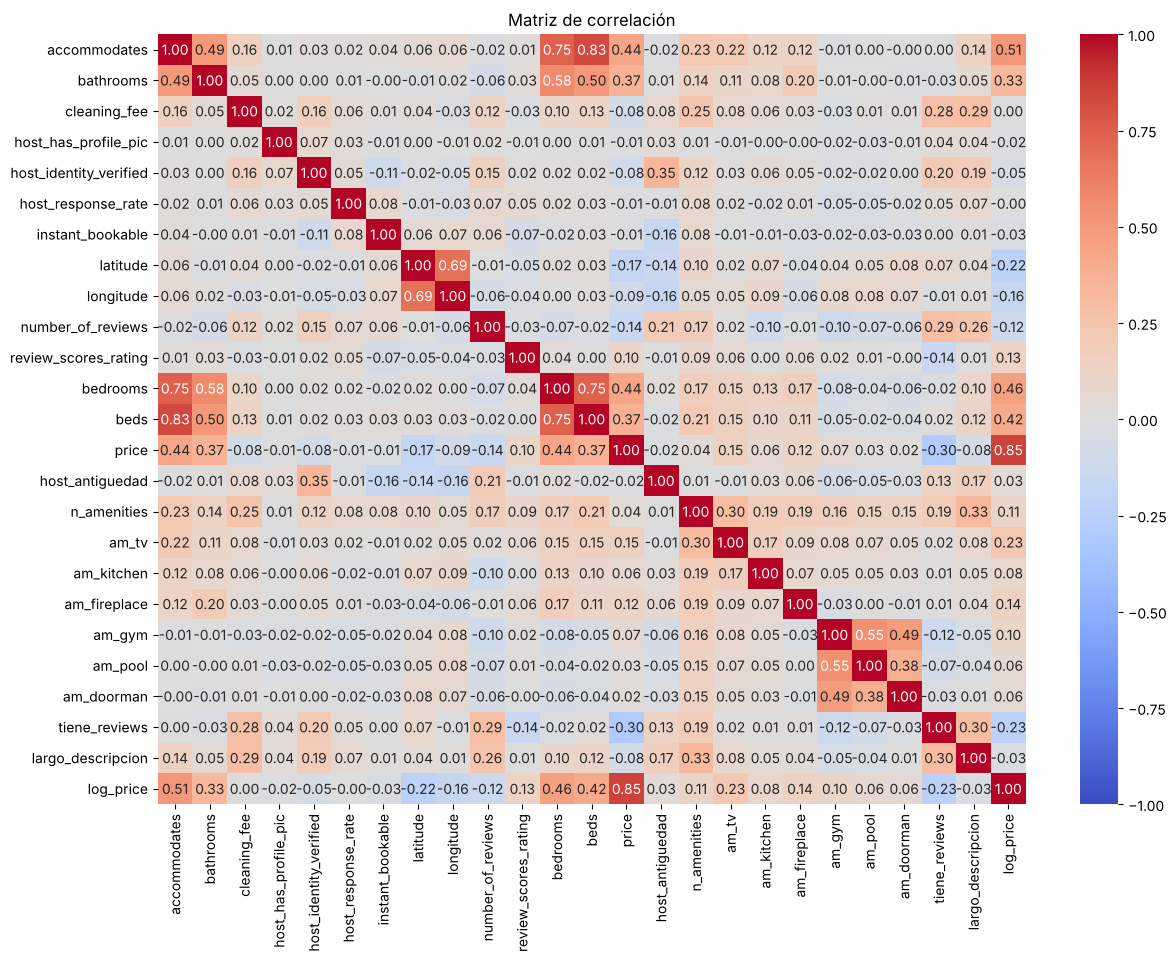

In [64]:
# Matriz de correlación lineal (Pearson) de las variables numéricas
corr = df.select_dtypes(include='number').corr()

# Mapa de calor
plt.figure(figsize=(14,10))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matriz de correlación')
plt.show()

In [65]:
# Correlación de cada variable con el log(precio), ordenada de mayor a menor
corr['log_price'].sort_values(ascending=False)

log_price                 1.000000
price                     0.853889
accommodates              0.513994
bedrooms                  0.462302
beds                      0.420173
bathrooms                 0.334683
am_tv                     0.234318
am_fireplace              0.139181
review_scores_rating      0.125661
n_amenities               0.111361
am_gym                    0.104892
am_kitchen                0.082775
am_pool                   0.062827
am_doorman                0.059965
host_antiguedad           0.032946
cleaning_fee              0.003939
host_response_rate       -0.003982
host_has_profile_pic     -0.017100
largo_descripcion        -0.030554
instant_bookable         -0.033779
host_identity_verified   -0.050546
number_of_reviews        -0.122364
longitude                -0.161740
latitude                 -0.224893
tiene_reviews            -0.231526
Name: log_price, dtype: float64

In [66]:
# Las variables más correlacionadas con el precio son las del tamaño de la propiedad:
# Huespedes (0.51), Habitaciones (0.46), Camas (0.42) y Baños (0.33). Es una correlación positiva y moderada
# Las demás variables tienen correlación muy baja (menor a 0.15), por lo que solas no explican el precio
# Entre las variables, accommodates y bedrooms están muy correlacionadas (0.75): dan información parecida (a más cuartos, más huéspedes). Se genera una redundancia

## Cantidad de huéspedes

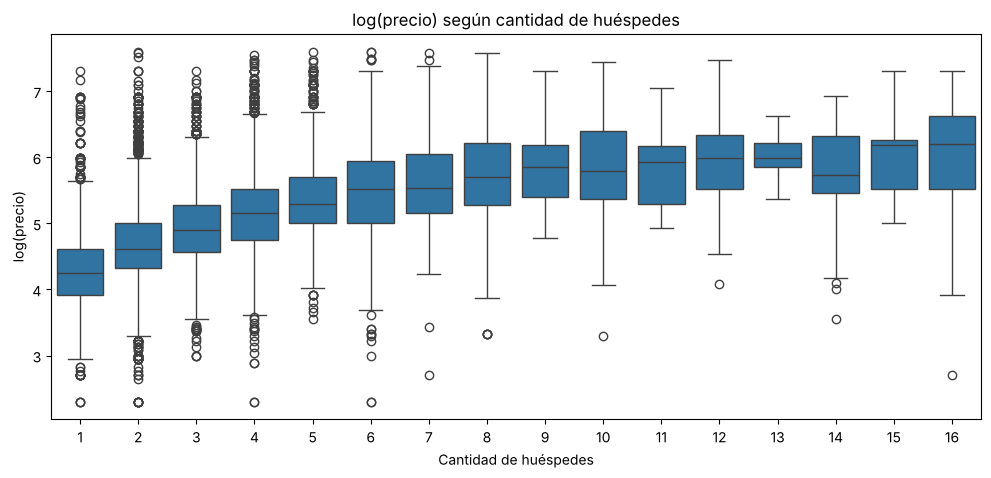

In [67]:
# Boxplot del log(precio) según la cantidad de huéspedes
plt.figure(figsize=(12,5))
sns.boxplot(data=df, x='accommodates', y='log_price')
plt.title('log(precio) según cantidad de huéspedes')
plt.xlabel('Cantidad de huéspedes')
plt.ylabel('log(precio)')
plt.show()

In [68]:
# Mientras más huéspedes admite la propiedad, más alto es el precio: la mediana va de 70 USD (1 huésped) a 300 USD (8 huéspedes)
# A partir de 10 huéspedes hay pocas publicaciones y el precio varía más

## Cantidad de cuartos

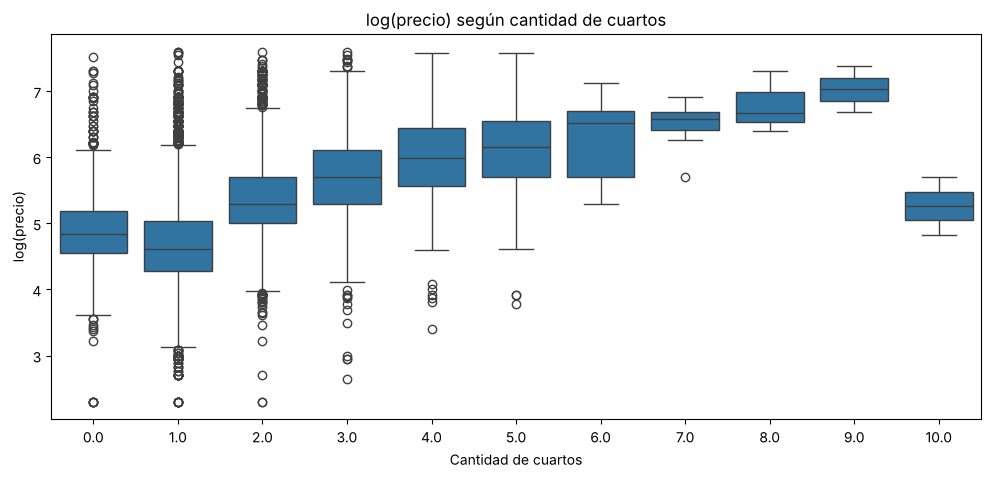

In [69]:
# Boxplot del log(precio) según la cantidad de cuartos
plt.figure(figsize=(12,5))
sns.boxplot(data=df, x='bedrooms', y='log_price')
plt.title('log(precio) según cantidad de cuartos')
plt.xlabel('Cantidad de cuartos')
plt.ylabel('log(precio)')
plt.show()

In [70]:
# Igual que con los huéspedes, a partir de 1 cuarto, a más cuartos más precio
# Las publicaciones con 0 cuartos son monoambientes (estudios) y salen un poco más que las de 1 cuarto, porque muchas de 1 cuarto son habitaciones privadas
# Con 10 cuartos el precio baja, pero hay muy pocas publicaciones así que no es representativo

# Ubicación

## Mapa de precios por ciudad

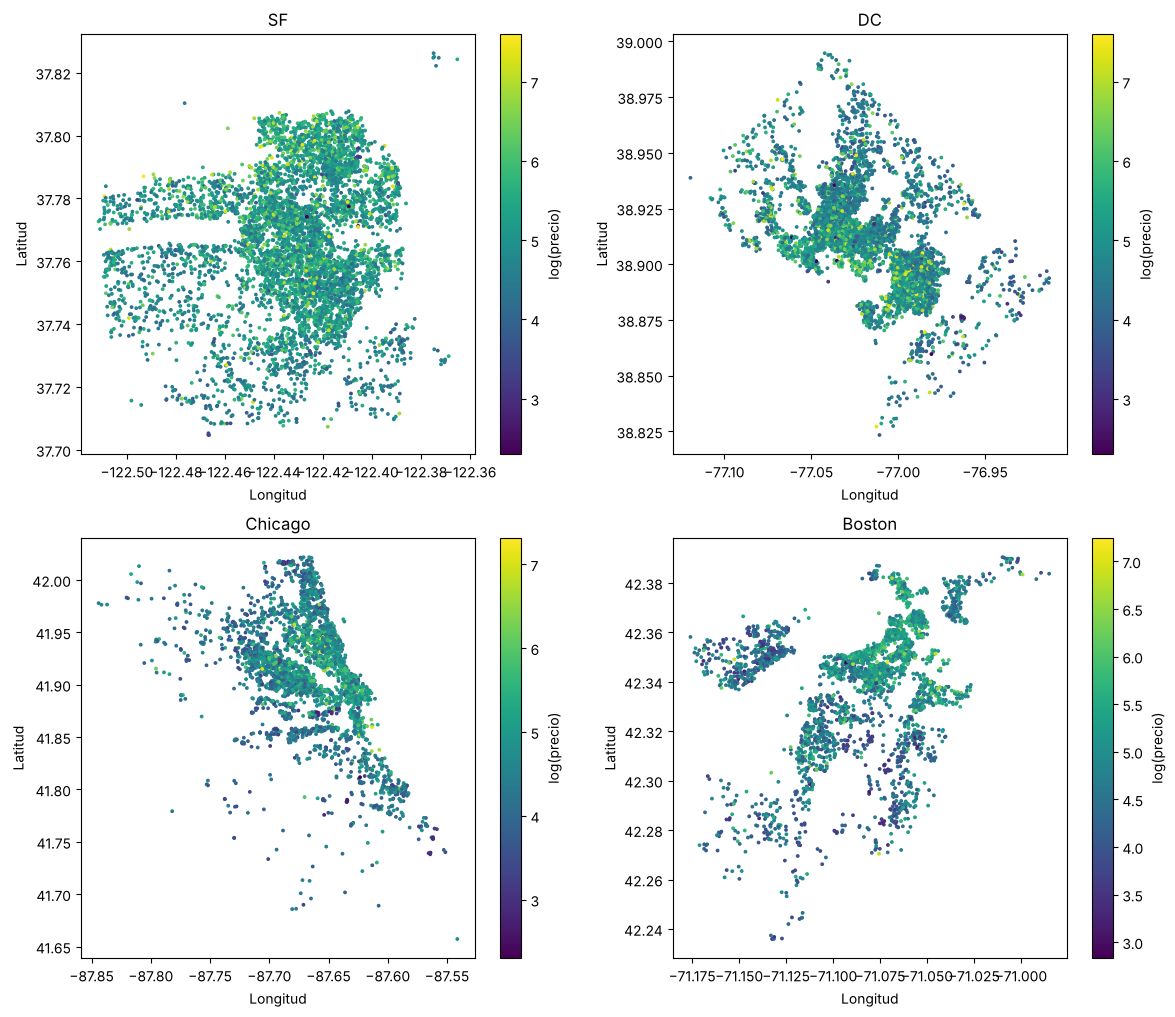

In [71]:
# Lista de ciudades
ciudades = ['SF', 'DC', 'Chicago', 'Boston']

plt.figure(figsize=(14,12))

# Hago un gráfico por ciudad, con cada publicación como un punto coloreado según su log(precio)
for i, ciudad in enumerate(ciudades, start=1):
    df_ciudad = df[df['city'] == ciudad]
    plt.subplot(2, 2, i)
    plt.scatter(df_ciudad['longitude'], df_ciudad['latitude'], c=df_ciudad['log_price'], cmap='viridis', s=3)
    plt.colorbar(label='log(precio)')
    plt.title(ciudad)
    plt.xlabel('Longitud')
    plt.ylabel('Latitud')

plt.show()

In [72]:
# Los precios más altos (puntos amarillos) se concentran en el centro de cada ciudad y cerca del agua
# Hacia las afueras los precios bajan
# Esto muestra que la ubicación dentro de la ciudad también influye en el precio

## Barrios más caros y más baratos

In [73]:
# Mediana del precio y cantidad de publicaciones por barrio
barrios = df.groupby('neighbourhood')['price'].agg(['median', 'count'])

# Me quedo con los barrios que tienen al menos 30 publicaciones para que sea representativo
barrios = barrios[barrios['count'] >= 30].sort_values('median')

# 5 barrios más baratos
print(barrios.head(5))

# 5 barrios más caros
print(barrios.tail(5))

                median  count
neighbourhood                
West Ridge        45.0     37
Little Village    51.0     35
Garfield Park     53.0     31
Anacostia         65.0     32
Avondale          67.5     74
                       median  count
neighbourhood                       
Cow Hollow              220.0     71
Marina                  225.0    129
Judiciary Square        229.0     55
Fisherman's Wharf       267.5     36
Downtown/Penn Quarter   297.0    111


In [74]:
# Los barrios más caros son céntricos o turísticos, con medianas de más de 220 USD
# Los más baratos están en las afueras de Chicago y DC, con medianas de 45 a 65 USD
# Entre barrios hay más diferencia de precio que entre ciudades

# Conclusiones

In [75]:
# - El precio tiene una distribución muy asimétrica, con outliers caros (8%). Usar log(precio) la vuelve casi simétrica, por eso conviene predecir log(precio)
# - El tamaño de la propiedad es lo que más influye: cantidad de huéspedes, cuartos, camas y baños (correlación de 0.33 a 0.51)
# - El tipo de habitación es la variable categórica más importante: la propiedad entera cuesta el doble que una habitación privada
# - La ubicación influye: San Francisco es la ciudad más cara y Chicago la más barata, y dentro de cada ciudad el centro es más caro
# - Los precios muy altos de DC se explican en parte por la inauguración presidencial de enero 2017 (314 publicaciones con mediana de 500 USD)
# - Algunas amenities poco comunes (chimenea, gimnasio, pileta, portero) se asocian a precios más altos, y las publicaciones sin reviews son más caras
# - La política de cancelación y el cargo de limpieza influyen poco. Las variables del host (verificado, foto, tasa de respuesta) casi no influyen
# - Algunas variables están muy correlacionadas entre sí (accommodates y bedrooms 0.75), lo cual justifica probar una reducción de dimensionalidad (PCA)

# Guardar dataset limpio

In [76]:
# Guardo el dataset limpio para usarlo en el notebook de Machine Learning
df.to_csv('airbnb_limpio.csv', index=False)